# IMGS 609 Homework 1
## Getting Started with Jupyter Notebooks
### Jonathan Lutzer 11/09/2026

My research interests are a bit all over the place, though primarily within remote sensing. My current QE project is looking at using synthetic aperture radar, SAR, to detect buried unexploded ordnance, and SAR relies heavily on computational techniques to process the radar phase history data into an image. I was also very interested in Michael Gartley's space domain awareness work when I was initially looking at the program; he has used DIRSIG to simulate imagery by actual telescopes and his work on satellite underflight images involves deconvolving the streak of "other satellite" in LANDSAT data, a task that relies heavily on computational processes.

Getting the formatting fun out of the way so that I don't forget to do it (I'll remove anything I remember to work in more naturally):
* I've been using Markdown via Discord for years, and learned a bunch of the formatting when I was on the Humans Versus Zombies club eboard in undergrad (so that I could format announcements)
* **Bold** and ***bolded italics*** are fun.
* Discord also lets you do subtext by putting a minus sign in front of a header hash like so: `-# This would appear as smaller-than-normal text`
* It's not required for the assignment and I'm not entirely sure if/when it would come up professionally, but I like using ~~strikethrough~~ formatting (`~~strikethrough~~`) when I edit text but want my original text to be clear for some reason. It mostly comes up if I've been corrected on something and want to edit the original message to head off any repeat corrections while leaving the context of the original message text. Outside of professional contexts, it's also useful for simple text-based jokes.

In [1]:
print("Hello! This is a short welcome message!")

Hello! This is a short welcome message!


In [2]:
a = 2
#b = 4
b = 5

sum_a_b = a + b
prod_a_b = a * b

print("a + b =", sum_a_b)
print("a * b =", prod_a_b)

a + b = 7
a * b = 10


In [3]:
import numpy as np
import matplotlib.pyplot as plt
# I've jumped to importing just pyplot, since I know it'll
# be used later on, and re-importing after importing the
# whole thing feels wrong.

A code cell is interpreted as Python code (or whatever language the notebook is written in), while a Markdown cell is not. Meanwhile, a Markdown cell can be formatting using... well, Markdown formatting, which won't work in a code cell.

The order code cells are executed in matters because they update objects in memory. If a cell references an object in another cell that hasn't been run yet, that object doesn't exist in memory yet. And if the code in a cell changes the value of a global variable, the cells run after it will use the updated value.

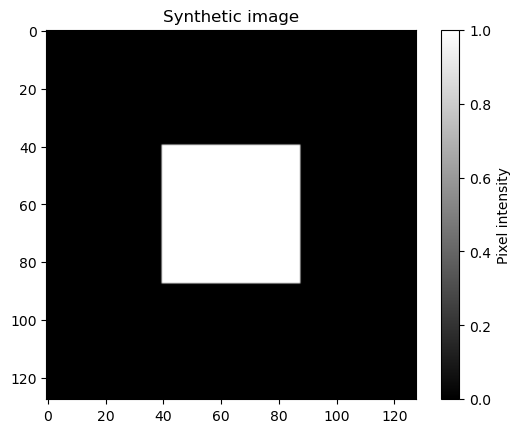

Image is 128 by 128 pixels
Maximum intensity = 1.0
Minimum intensity = 0.0
Mean intensity = 0.140625


In [4]:
# I have already imported numpy and pyplot above

image = np.zeros((128, 128))
image[40:88, 40:88] = 1.0

plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Synthetic image")
plt.colorbar(label="Pixel intensity")
plt.show()

dims = np.shape(image)
print(f"Image is {dims[0]} by {dims[1]} pixels")

print(f"Maximum intensity = {np.max(image)}")

print(f"Minimum intensity = {np.min(image)}")

print(f"Mean intensity = {np.average(image)}")


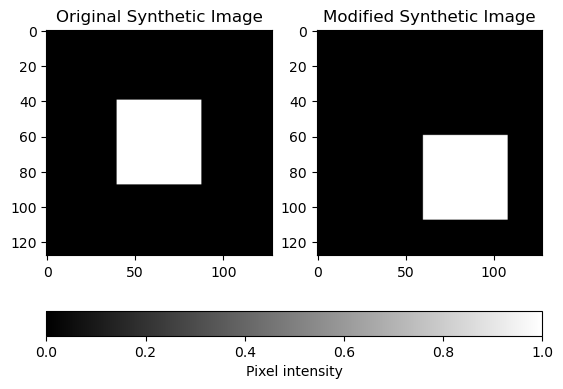

Mean intensity of image2 = 0.140625


In [5]:
image2 = np.zeros((128, 128))
image2[40+20:88+20, 40+20:88+20] = 1.0

fig, axs = plt.subplots(1, 2)
ax1 = axs[0]
ax2 = axs[1]

img1 = ax1.imshow(image, cmap="gray", vmin=0, vmax=1)
ax1.set_title("Original Synthetic Image")

img2 = ax2.imshow(image2, cmap="gray", vmin=0, vmax=1)
ax2.set_title("Modified Synthetic Image")

plt.colorbar(img1, ax = axs, orientation = 'horizontal', label="Pixel intensity")

plt.show()

print(f"Mean intensity of image2 = {np.average(image2)}")

My modification did not change the mean intensity, since the white square is the same size as in the original image and the overall image size is the same. The only change was to the location of the square within the image, which doesn't affect the calculation of the mean.

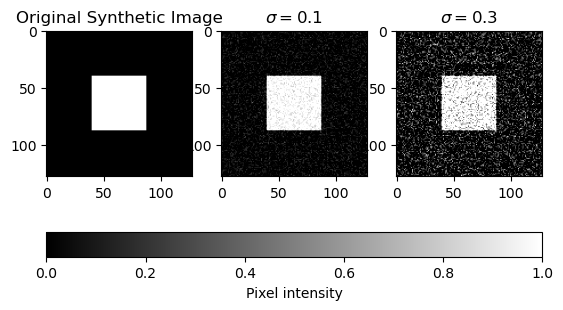

In [6]:
rng = np.random.default_rng(42)
noisy_image = image + rng.normal(0, 0.1, image.shape)
noisy_image_larger_stdev = image + rng.normal(0, 0.3, image.shape)

fig, axs = plt.subplots(1, 3)
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]

img1 = ax1.imshow(image, cmap="gray", vmin=0, vmax=1)
ax1.set_title("Original Synthetic Image")

img2 = ax2.imshow(noisy_image, cmap="gray", vmin=0, vmax=1)
ax2.set_title("$\\sigma = 0.1$")

img3 = ax3.imshow(noisy_image_larger_stdev, cmap="gray", vmin=0, vmax=1)
ax3.set_title("$\\sigma = 0.3$")

plt.colorbar(img1, ax = axs, orientation = 'horizontal', label="Pixel intensity")

plt.show()


Increasing the noise level reduced the visibility of the square, since the edges became less clean. While it's not difficult to pick out as a human viewer, I'd imagine that noise like this makes computer vision... interesting.

Using the same intensity display limits functionally normalizes the image intensities, preventing differently-scaled data in one image from making the other images indistinct/washed-out. Additionally (though this is more of a quality of life matter for the programmer), it makes applying a colorbar to the image when plotting multiple images together *way* easier, since you don't have to account for the different ranges of data among your images.